<h2>读入数据集并分析</h2>

In [4]:
import numpy as np
import pandas as pd

data=pd.read_csv(r"breast-cancer-wisconsin.data",',',encoding='utf-8')   #读取数据集
#显示数据集的前五条
header=['id','clump','cellsize','cellshape','adhesion','single','bare','bland','nucleoli','mitoses','class']
data.columns=header
print(data.head())

        id  clump  cellsize  cellshape  adhesion  single bare  bland  \
0  1002945      5         4          4         5       7   10      3   
1  1015425      3         1          1         1       2    2      3   
2  1016277      6         8          8         1       3    4      3   
3  1017023      4         1          1         3       2    1      3   
4  1017122      8        10         10         8       7   10      9   

   nucleoli  mitoses  class  
0         2        1      2  
1         1        1      2  
2         7        1      2  
3         1        1      2  
4         7        1      4  


D:\anacondainstall\lib\site-packages\IPython\core\interactiveshell.py:3331: FutureWarning: In a future version of pandas all arguments of read_csv except for the argument 'filepath_or_buffer' will be keyword-only
  exec(code_obj, self.user_global_ns, self.user_ns)


In [5]:
print(data.columns)     #查看有哪些特征
print('删除前的数据集大小为:{}'.format(data.shape))
data.drop_duplicates(inplace=True)  #删除重复数据
data.replace('?', pd.NA, inplace=True)
data.dropna(inplace=True)   #删除缺失值
print('删除后的数据集大小为:{}'.format(data.shape))
data=data.drop(columns=['id'])  #删除id列
# data.to_excel('cancer.xlsx', sheet_name='data') #写到excel里方便分析一下

Index(['id', 'clump', 'cellsize', 'cellshape', 'adhesion', 'single', 'bare',
       'bland', 'nucleoli', 'mitoses', 'class'],
      dtype='object')
删除前的数据集大小为:(698, 11)
删除后的数据集大小为:(674, 11)


In [6]:
#查看质量的分布情况
data['class'].value_counts()

2    438
4    236
Name: class, dtype: int64

<h2>评估指标相关函数</h2>

<h3>一、定义绘制混淆矩阵的函数</h3>

In [7]:
from sklearn import metrics
from sklearn.metrics import classification_report
import itertools
import matplotlib.pyplot as plt
import numpy as np
# 绘制混淆矩阵
def plot_confusion_matrix(cm, classes, title='Confusion matrix', cmap=plt.cm.Blues):
    plt.imshow(cm, interpolation='nearest', cmap=cmap)
    plt.title(title)
    plt.colorbar()
    tick_marks = np.arange(len(classes))
    plt.xticks(tick_marks, classes)
    plt.yticks(tick_marks, classes)
    plt.ylim(len(classes) - 0.5, -0.5)
    fmt =  'd'
    thresh = cm.max() / 2.
    for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
        plt.text(j, i, format(cm[i, j], fmt),
                 horizontalalignment="center",
                 color="white" if cm[i, j] > thresh else "black")
    plt.tight_layout()
    plt.ylabel('True label')
    plt.xlabel('Predicted label')
    plt.show()

<h3>二、定义绘制ROC曲线的函数</h3>

In [8]:
from sklearn.metrics import roc_curve, auc
def plot_roc_curve(y,score):
    fpr, tpr, thresholds = roc_curve(y, score)

    # 计算AUC
    roc_auc = auc(fpr, tpr)

    # 绘制ROC曲线
    plt.title('Receiver Operating Characteristic')
    plt.plot(fpr, tpr, 'b', label = 'AUC = %0.4f' % roc_auc)
    plt.legend(loc = 'lower right')
    plt.plot([0, 1], [0, 1],'r--')
    plt.xlim([0, 1])
    plt.ylim([0, 1])
    plt.ylabel('True Positive Rate')
    plt.xlabel('False Positive Rate')
    plt.show()

<h2>事前准备：创建训练集和测试集</h2>

In [9]:
n=0.8
data = data.apply(pd.to_numeric)
classnumber=data.value_counts()

bad=data[data["class"]==4]
good=data[data["class"]==2]

bad=bad.sample(len(bad),random_state=0)
good=good.sample(len(good),random_state=0)

#分层抽样后相连,创建训练集和测试集
train_X=pd.concat([bad.iloc[:int(len(bad)*0.8),:-1],good.iloc[:int(len(good)*0.8),:-1]],axis=0)
train_y=pd.concat([bad.iloc[:int(len(bad)*0.8),-1],good.iloc[:int(len(good)*0.8),-1]],axis=0)
test_X=pd.concat([bad.iloc[int(len(bad)*0.8):,:-1],good.iloc[int(len(good)*0.8):,:-1]],axis=0)
test_y=pd.concat([bad.iloc[int(len(bad)*0.8):,-1],good.iloc[int(len(good)*0.8):,-1]],axis=0)

#重新赋值，把恶性赋值为1，把良性赋值为0
train_y=np.where(train_y==4,1,train_y)
train_y=np.where(train_y==2,0,train_y)
test_y=np.where(test_y==4,1,test_y)
test_y=np.where(test_y==2,0,test_y)

#做归一化处理后再进行knn训练
# min_val = train_X.min()
# max_val = train_X.max()
# train_X = (train_X - min_val) / (max_val - min_val)
#
# min_val = test_X.min()
# max_val = test_X.max()
# test_X = (test_X - min_val) / (max_val - min_val)

In [10]:
X_train=np.asarray(train_X)
y_train=np.asarray(train_y)
X_test=np.asarray(test_X)
y_test=np.asarray(test_y)

<h1>特征选择</h1>

In [16]:
accuracy=[] #存放每个特征的准确率
k=7

for i in range(X_train.shape[1]):
    result=[]   #存放预测结果
    for x in X_test:
        dis=(x-X_train) ** 2
        dis=dis.transpose()
        subdis=dis[i]
        index=subdis.argsort()     #返回数组排序后数组元素的索引
        index=index[:k]
        count=np.bincount(y_train[index])      #返回数组中元素出现的次数，必须是自然数
        result.append(count.argmax())     #返回出现最多元素的索引
    num_correct = np.sum(result == y_test)
    accuracy .append( num_correct / len(y_test))


print(accuracy)

[0.8897058823529411, 0.9338235294117647, 0.9264705882352942, 0.875, 0.9338235294117647, 0.8529411764705882, 0.9191176470588235, 0.8897058823529411, 0.7720588235294118]


<h1>一、KNN算法的实现</h1>可以多分类，数值特征即可

<h3>knn类的编写</h3>

In [8]:
class KNN:
    #初始化方法，k为选择的邻居个数
    def __init__(self,k):
        self.k=k

    def fit(self,X,y):
        """
        训练方法，在KNN算法中仅仅是转换数据类型格式，使得传进来的X和y可以是多种数据类型
        :parameters
        -----
        X:训练样本，形状为[样本数，特征数]
        y:训练样本的实际值，形状为[样本数]
        """
        self.X=np.asarray(X)
        self.y=np.asarray(y)

    def predict(self,X):
        """
        预测方法
        :param X:预测样本，形状为[样本数，特征数]
        -----
        :return:
        -----
         result:预测结果，是测试集预测结果的合集
        """
        X=np.asarray(X)
        result=[]
        score=[]
        for x in X:
            dis=np.sum((x-self.X) ** 2,axis=1)     #计算距离，此时每行元素即为测试样本到训练样本的距离的平方
            index=dis.argsort()     #返回数组排序后数组元素的索引
            index=index[:self.k]
            count=np.bincount(self.y[index])      #返回数组中元素出现的次数，必须是自然数
            result.append(count.argmax())     #返回出现最多元素的索引
            score.append(count[0]/self.k)

        return np.asarray(result),score

<h3>knn类的训练</h3>

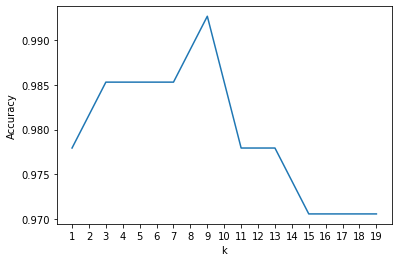

In [24]:
x=[]
accuracy=[]
for i in range(10):
    x.append(2*i+1)
    knn=KNN(k=2*i+1)
    knn.fit(train_X,train_y)
    result,score=knn.predict(test_X)
    num_correct = np.sum(result == test_y)
    accuracy .append( num_correct / len(test_y))


plt.plot(x,accuracy)
plt.xticks(range(min(x), max(x)+1, 1))
plt.ylabel('Accuracy')
plt.xlabel('k')
plt.show()

In [25]:
knn=KNN(k=9)
knn.fit(train_X,train_y)
result,score=knn.predict(test_X)
# num_correct = np.sum(result == test_y)
# accuracy .append( num_correct / len(test_y))

<h3>输出评价指标</h3>

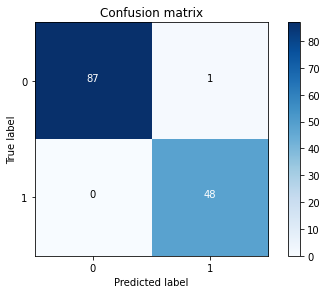

              precision    recall  f1-score   support

           0       1.00      0.99      0.99        88
           1       0.98      1.00      0.99        48

    accuracy                           0.99       136
   macro avg       0.99      0.99      0.99       136
weighted avg       0.99      0.99      0.99       136



In [26]:
from sklearn import metrics
from sklearn.metrics import classification_report

matrix=metrics.confusion_matrix(test_y, result, labels=None, sample_weight=None)
classes=['0','1']
plot_confusion_matrix(matrix, classes, title='Confusion matrix', cmap=plt.cm.Blues)
# y_true是真实的类别标签，y_pred是预测的类别标签
print(classification_report(test_y, result))

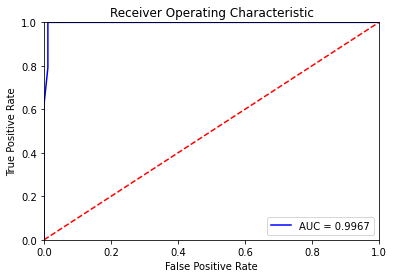

In [27]:
y_test=np.asarray(test_y)
score=[1-x for x in score]
plot_roc_curve(y_test,score)

<font color="red">可以看到准确率很高，说明10个特征基本都是有用的，且权值大致相等，分布集中，所以分类效果较好

<h1>二、朴素贝叶斯决策算法的实现</h1>多分类应该也可以，该贝叶斯是多项式贝叶斯，输入需为离散量，要解决连续问题或许另写高斯贝叶斯

<h3>朴素贝叶斯类的编写</h3>

In [28]:
class NaiveBayes:

    def __init__(self):

        self.lablepl={}  #用来存放类条件概率的字典{类别名：出现概率}
        self.features=[]    #计算每个特征出现的概率

    def fit(self,X_train,y_train):
        self.X_train=np.asarray(X_train)
        self.y_train=np.asarray(y_train)

        #1、计算类条件概率
        # 统计元素出现的次数
        self.labels, self.counts = np.unique(self.y_train, return_counts=True)
        # 将元素名和元素个数转换为字典格式
        count_dict = dict(zip(self.labels, self.counts))
        for k,v in count_dict.items():
            self.lablepl[k]=v/len(self.y_train)

        #2、计算每个特征出现的概率
        numberf=len(self.X_train[0])
        for label in self.labels:
            feature=[]
            for j in range(numberf):    #按照特征数往feature里加入空字典
                feature.append({})
            for i in range(len(self.y_train)):   #取出一条数据
                if self.y_train[i]==label:
                    for k in range(len(self.X_train[0])):
                        if self.X_train[i][k] not in feature[k]:
                            feature[k][self.X_train[i][k]]=1
                        else:
                            feature[k][self.X_train[i][k]]=feature[k][self.X_train[i][k]]+1
            self.features.append(feature)

        for i in range(len(self.labels)):
            for j in range(len(self.X_train[0])):
                for key in self.features[i][j]:
                    self.features[i][j][key]=self.features[i][j][key]/self.counts[i]

    def predict(self,X_test):
        self.X_test=np.asarray(X_test)
        result=[]
        possiblity=[]
        # for i in range(len(y_test)):    #取出一条测试样本
        for x in self.X_test:
            possible=[]
            for j in range(len(self.labels)):    #分别计算两种标签的概率
                sum=0
                for k in range(len(self.X_test[0])):
                    if x[k] in self.features[j][k]:  #如果测试集的值有在训练集出现过就取出对应概率
                        sum=sum+np.log(self.lablepl[self.labels[j]])  #labels的下标对应的值是labelpl的key
                    else:   #否则按平滑处理
                        sum=sum+np.log(1.0/self.counts[j])
                sum=sum+np.log(self.lablepl[self.labels[j]])
                possible.append(sum)
            possiblity.append(possible)
            index=np.argmax(possible)
            result.append(self.labels[index])
        return result,possiblity

<h3>训练贝叶斯分类器</h3>

In [29]:
nbclasser=NaiveBayes()
nbclasser.fit(train_X,train_y)
result,possiblity=nbclasser.predict(test_X)

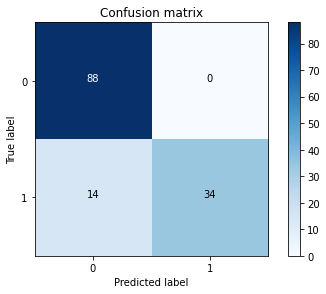

              precision    recall  f1-score   support

           0       0.86      1.00      0.93        88
           1       1.00      0.71      0.83        48

    accuracy                           0.90       136
   macro avg       0.93      0.85      0.88       136
weighted avg       0.91      0.90      0.89       136



In [30]:
matrix=metrics.confusion_matrix(test_y, result, labels=None, sample_weight=None)
classes=['0','1']
plot_confusion_matrix(matrix, classes, title='Confusion matrix', cmap=plt.cm.Blues)
# y_true是真实的类别标签，y_pred是预测的类别标签
print(classification_report(test_y, result))

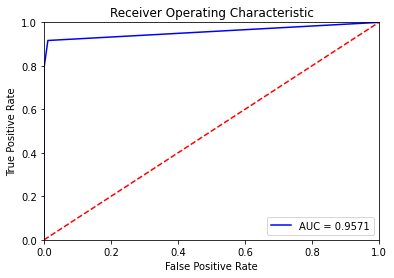

In [98]:
score=[]
for i in range(len(y_test)):
    score.append(possiblity[i][0]/(possiblity[i][0]+possiblity[i][1]))
plot_roc_curve(y_test,score)

可以看到准确率并不高，2能够百分百准确，但4不行，考虑应该是因为该朴素贝叶斯是离散式的朴素贝叶斯，有些特征值在训练集出现了，但在测试集并未出现，所以此时类概率就成了判定因素，但2类又远远高于4类，导致产生了这种情况。

<h1>二（改）、以高斯分布估计概率的朴素贝叶斯实现<h1>

In [155]:
def normal_distribution(x,mean,variance):
        return (1 / ( math.sqrt(2 * variance * math.pi))) * math.exp(-((x - mean) ** 2) / (2 * variance))

In [200]:
import math
class NaiveBayes:

    def __init__(self):

        self.lablepl={}  #用来存放类条件概率的字典{类别名：出现概率}
        self.dic={}  #键为标签，值为一个存有均值和方差的列表


    def fit(self,X_train,y_train):
        self.X_train=np.asarray(X_train)
        self.y_train=np.asarray(y_train)

        #1、计算类条件概率
        # 统计元素出现的次数
        self.labels, self.counts = np.unique(self.y_train, return_counts=True)
        # 将元素名和元素个数转换为字典格式
        count_dict = dict(zip(self.labels, self.counts))
        for k,v in count_dict.items():
            self.lablepl[k]=v/len(self.y_train)

        #2、每列特征出现的均值和方差
        numberf=len(self.X_train[0])
        for label in self.labels:
            subx=X_train[y_train==label]
            he=[]   #第一个元素为均值，第二个元素为方差
            means=np.mean(subx,axis=0)
            he.append(means)
            variance = np.var(subx, axis=0,ddof=1)
            he.append(variance)
            self.dic[label]=he


    def predict(self,X_test):
        self.X_test=np.asarray(X_test)
        result=[]
        score=[]
        for x in self.X_test:   #取出一条测试样本
            possible=[]
            # print(x)
            for key,value in self.dic.items():
                sum=0
                for i in range(len(x)):
                    sum+=np.log(normal_distribution(x[i],value[0][i],value[1][i]))
                sum=sum+np.log(self.lablepl[key])
                possible.append(sum)
            index=np.argmax(possible)
            result.append(index)
            score.append(possible[0]/(possible[0]+possible[1]))

        return result,score

nbclasser=NaiveBayes()
nbclasser.fit(train_X,train_y)
result,score=nbclasser.predict(test_X)

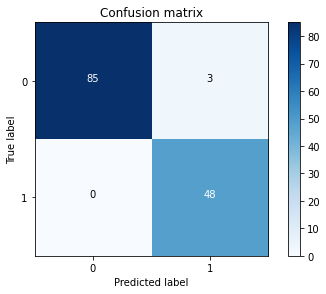

              precision    recall  f1-score   support

           0       1.00      0.97      0.98        88
           1       0.94      1.00      0.97        48

    accuracy                           0.98       136
   macro avg       0.97      0.98      0.98       136
weighted avg       0.98      0.98      0.98       136



In [196]:
matrix=metrics.confusion_matrix(test_y, result, labels=None, sample_weight=None)
classes=['0','1']
plot_confusion_matrix(matrix, classes, title='Confusion matrix', cmap=plt.cm.Blues)
# y_true是真实的类别标签，y_pred是预测的类别标签
print(classification_report(test_y, result))

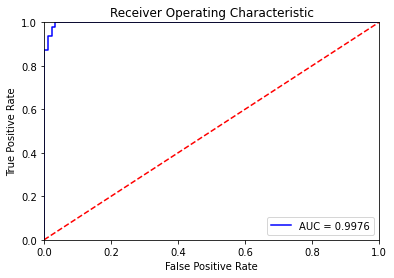

In [203]:
plot_roc_curve(y_test,score)

<h1>三、决策树的实现</h1>多分类应该也可以用，连续量要先处理成离散量再使用

In [55]:
X_train=np.asarray(train_X)
y_train=np.asarray(train_y)
X_test=np.asarray(test_X)
y_test=np.asarray(test_y)

#1、最优二分法划分最佳分割点，把特征变为离散量

def optimal_split(X, y):
    # 计算数据集的信息熵
    entropy = 0
    for value in set(y):
        p = y[y == value].size / y.size
        entropy -= p * np.log2(p)

    # 初始化最大信息
    # 从最小值到最大值枚举每个可能的分割点
    optimal_split_point=[]
    for i in range(len(X.T[0])):    #9个特征
        best_value=0
        max_gain=0
        for value in set(X[i]):
            # 计算左子集和右子集的信息熵
            left_y = y[X[i] <= value]
            right_y = y[X[i] > value]
            left_entropy = 0
            right_entropy = 0
            for val in set(left_y):
                p = left_y[left_y == val].size / left_y.size
                left_entropy -= p * np.log2(p)
            for val in set(right_y):
                p = right_y[right_y == val].size / right_y.size
                right_entropy -= p * np.log2(p)

            # 计算信息增益
            gain = entropy - (left_y.size / y.size) * left_entropy - (right_y.size / y.size) * right_entropy
            if gain > max_gain:
                max_gain = gain
                best_value=value
        optimal_split_point.append(best_value)

    return optimal_split_point

sep=optimal_split(X_train.T, y_train)
print(sep)

[6, 2, 2, 2, 2, 2, 3, 2, 1]


In [58]:
# #2、重新整理数据集
X=np.copy(X_train)
for i in range(X.shape[0]):
    for j in range(len(sep)):
        if X[i][j]<=sep[j]:
            X[i][j]=0
        else:
            X[i][j]=1

[[1 1 1 0 1 1 1 0 0]
 [0 1 1 1 1 0 0 1 0]
 [1 1 1 0 1 1 1 1 1]
 [1 1 1 1 1 1 1 0 1]
 [1 1 1 1 1 1 1 1 1]]
[[10  8 10  1  3 10  5  1  1]
 [ 3  4  4 10  5  1  3  3  1]
 [10  4  3  2  3 10  5  3  2]
 [10  5  8 10  3 10  5  1  3]
 [ 8 10 10 10  8 10 10  7  3]]


<h3>定义决策树训练过程</h3>

In [59]:
#3、建立决策树

def treefit(X,y,deep):
    # 如果所有样本属于同一类别，停止递归并返回叶子节点
    if len(set(y)) == 1:
        return y[0]

    # 如果没有特征可以用来分裂，或深度达到要求值，返回数据集中样本数最多的类别
    if X.shape[1] == 0 or deep==0:
        relabel=0
        for label in set(y):
            max=0
            if y[y==label].size > max:
                max=y[y==label].size
                relabel=label
        return relabel

    # 计算每个特征的信息增益
    gains = []
    for col in range(X.shape[1]):
        caculate=np.copy(X[:,col])  #取出了X中的每列
        gain=0
        for label in set(y):    #取出y中标签
            subxca=caculate[y==label]
            for feature in set(subxca):
                p=subxca[subxca==feature].size/subxca.size
                gain=gain-p*np.log2(p)
            gain=gain*y[y==label].size/y.size
        gain=-gain
        gains.append(gain)


    # 选择信息增益最大的特征进行分裂
    split_col = np.argmax(gains)    #返回gain最大值的下标
    split_value = X[:, split_col]   #split_value内存储的是要分裂的那一列特征

    # 建立子节点，递归调用 fit() 函数
    tree = {}
    for value in set(split_value):  #按照split_value内的值来挨个建立子节点
        sub_X = X[split_value == value]
        sub_y = y[split_value == value]
        deepnew=deep-1
        tree[value] = treefit(np.delete(sub_X, split_col, axis=1), sub_y,deepnew)

    return (split_col, tree)


In [62]:
tree=treefit(X,y_train,5)

In [64]:
X1=np.copy(X_test)
for i in range(X_test.shape[0]):
    for j in range(len(sep)):
        if X1[i][j]<=sep[j]:
            X1[i][j]=0
        else:
            X1[i][j]=1

print(X1)

[[1 1 0 ... 1 1 1]
 [0 1 1 ... 1 0 0]
 [0 0 1 ... 1 1 0]
 ...
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]]


In [65]:
def treepredict(tree, x):
    # 如果节点为叶子节点，直接返回预测结果
    # print(tree)
    if isinstance(tree, np.int64):
        return tree

    # 获取当前节点的特征编号和子节点字典
    split_col, sub_tree = tree
    split_value = x[split_col]

    if split_value not in sub_tree:
        for value in sub_tree:
            if isinstance(tree, np.int64):
                return sub_tree[value]
            else:
                return treepredict(sub_tree[value],x)
    # 递归调用 predict() 函数，直到遇到叶子节点
    return treepredict(sub_tree[split_value],x)

result=[]
for i in range(X1.shape[0]):
    result.append(treepredict(tree,X1[i]))
print(result)

[1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0]


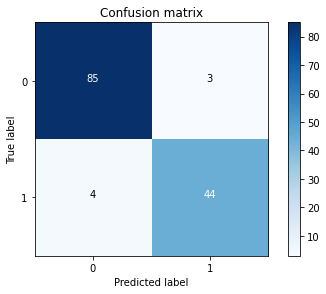

              precision    recall  f1-score   support

           0       0.96      0.97      0.96        88
           1       0.94      0.92      0.93        48

    accuracy                           0.95       136
   macro avg       0.95      0.94      0.94       136
weighted avg       0.95      0.95      0.95       136



In [66]:
matrix=metrics.confusion_matrix(test_y, result, labels=None, sample_weight=None)
classes=['0','1']
plot_confusion_matrix(matrix, classes, title='Confusion matrix', cmap=plt.cm.Blues)
# y_true是真实的类别标签，y_pred是预测的类别标签
print(classification_report(test_y, result))

<h1>四、fisher线性判别的实现</h1>

In [11]:
#1、重新赋值训练集和测试集

X_train=np.asarray(train_X)
y_train=np.asarray(train_y)
X_test=np.asarray(test_X)
y_test=np.asarray(test_y)

<h3>fisher线性判别的训练过程</h3>

In [29]:
def fisherfit(X_train,y_train):

    labelmean={}
    Sw = np.zeros((X_train.shape[1], X_train.shape[1]))

    for label in set(y_train):
        X_class = X_train[y_train == label]
        mean=np.mean(X_class, axis=0)
        labelmean[label]=mean
        for x in X_class:
            x = x.astype(np.float64)
            x-=mean
            x2=np.outer(x, x)
            Sw+=x2

    mean=labelmean[1]-labelmean[0]
    w=np.dot(np.linalg.inv(Sw),mean)



    X_train=np.asarray(train_X)
    w0=0    #w0为阈值
    w0dic={}

    for label in set(y_train):
        w1=0
        subX=X_train[y_train==label]
        for x in subX:
            w1+=np.dot(x,w)
        w1/=subX.shape[0]
        w0+=w1

    w0/=len(set(y_train))
    # for label in set(y_train):
    #     w1=0
    #     subX=X_train[y_train==label]
    #     for x in subX:
    #         w1+=0.5*np.dot(x,w)
    #     if w1<w0:
    #         w0dic[label]=w0
    #     break


    return w,w0

w,w0=fisherfit(X_train,y_train)
print("w*={}".format(w.transpose()))
print("w0={}".format(w0))

w*=[ 0.00155236  0.00103597  0.00075538  0.00046509  0.0005498   0.00232424
  0.00081431  0.00124311 -0.00028964]
w0=0.03622257727772203


In [30]:
def fisherpridect(X_test,w,w0):
    result=[]
    score=[]
    for x in X_test:
        th=np.dot(x,w)
        if th>w0:
            result.append(1)
        else:
            result.append(0)
        score.append(1 / (1 + np.exp(-(th-w0))))
    return result,score

In [31]:
result,score=fisherpridect(X_test,w,w0)

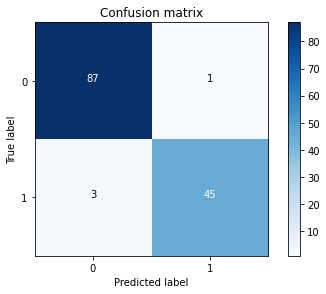

              precision    recall  f1-score   support

           0       0.97      0.99      0.98        88
           1       0.98      0.94      0.96        48

    accuracy                           0.97       136
   macro avg       0.97      0.96      0.97       136
weighted avg       0.97      0.97      0.97       136



In [32]:
matrix=metrics.confusion_matrix(test_y, result, labels=None, sample_weight=None)
classes=['0','1']
plot_confusion_matrix(matrix, classes, title='Confusion matrix', cmap=plt.cm.Blues)
# y_true是真实的类别标签，y_pred是预测的类别标签
print(classification_report(test_y, result))

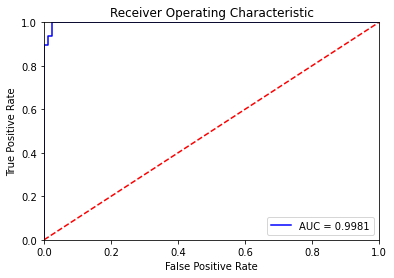

In [33]:
plot_roc_curve(y_test,score)

<h1>五、逻辑回归的实现</h1>

In [106]:
X_train=np.asarray(train_X)
y_train=np.asarray(train_y)
X_test=np.asarray(test_X)
y_test=np.asarray(test_y)

# #重新赋值，把恶性赋值为1，把良性赋值为0
# y_train=np.where(y_train==4,1,y_train)
# y_train=np.where(y_train==2,0,y_train)
# y_test=np.where(y_test==4,1,y_test)
# y_test=np.where(y_test==2,0,y_test)
# print(y_test)

#X都各加一列作为偏置
X_train = np.c_[np.ones(X_train.shape[0]),X_train]
X_test = np.c_[np.ones(X_test.shape[0]),X_test]
print(X_test.shape)

(136, 10)


In [107]:
#1、定义sigmoid函数
def sigmoid(x):
    return  1 / (1 + np.exp(-x))

In [125]:
#定义训练函数
learning_rate=0.01  #设置学习率
num_iterations=1000   #设置迭代次数
threshold=0.0003     #设置阈值，当梯度小于阈值的时候就会停止训练

def lrfit(X, y, learning_rate=0.1, num_iterations=1000, threshold=0.0003):

        #初始化权重
        theta = np.ones(X.shape[1])

        #初始化梯度值
        gradient=np.zeros(X.shape[1])

        #开始梯度下降训练
        for n in range(num_iterations):
            for j in range(X.shape[1]): #遍历每个特征
                jf=0

                for i in range(X.shape[0]): #遍历每个样本,计算所有样本的损失
                    z=np.dot(X[i],theta)
                    h=sigmoid(z)
                    jf+=(h-y[i])*X[i][j]

                jf/=X.shape[0]  #求平均值
                gradient[j]=jf

            theta=theta-learning_rate*gradient  #更新梯度
            if abs(gradient.sum()) <threshold:
                return theta

        return theta

In [126]:
theta=lrfit(X_train,y_train)
print(theta)

[-4.28842883  0.09805491  0.34979357  0.20036838  0.13603327 -0.13019823
  0.35478482 -0.03534985  0.25016616 -0.14318312]


In [127]:
def lrpredict(X_test,theta):
    result=[]
    score=[]
    for x in X_test:
        z=sigmoid(np.dot(x,theta))
        if z>0.5:
            result.append(1)
        else:
            result.append(0)
        score.append(z)
    return result,score

In [128]:
result,score=lrpredict(X_test,theta)

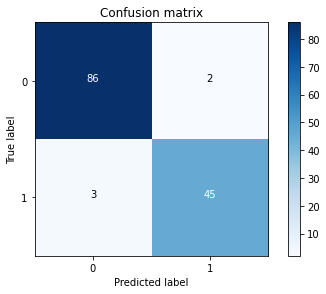

              precision    recall  f1-score   support

           0       0.97      0.98      0.97        88
           1       0.96      0.94      0.95        48

    accuracy                           0.96       136
   macro avg       0.96      0.96      0.96       136
weighted avg       0.96      0.96      0.96       136



In [129]:
matrix=metrics.confusion_matrix(y_test, result, labels=None, sample_weight=None)
classes=['0','1']
plot_confusion_matrix(matrix, classes, title='Confusion matrix', cmap=plt.cm.Blues)
# y_true是真实的类别标签，y_pred是预测的类别标签
print(classification_report(y_test, result))

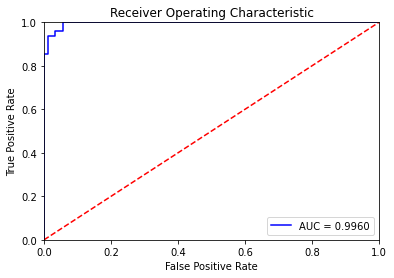

In [130]:
plot_roc_curve(y_test,score)

In [131]:
theta=lrfit(X_train,y_train,num_iterations=5000)
print(theta)

[-7.46295962  0.36684873  0.07987361  0.25379312  0.24423727  0.05228676
  0.34547901  0.25574742  0.23002701  0.13002997]


In [132]:
result,score=lrpredict(X_test,theta)

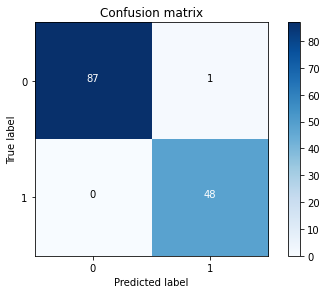

              precision    recall  f1-score   support

           0       1.00      0.99      0.99        88
           1       0.98      1.00      0.99        48

    accuracy                           0.99       136
   macro avg       0.99      0.99      0.99       136
weighted avg       0.99      0.99      0.99       136



In [133]:
matrix=metrics.confusion_matrix(y_test, result, labels=None, sample_weight=None)
classes=['0','1']
plot_confusion_matrix(matrix, classes, title='Confusion matrix', cmap=plt.cm.Blues)
# y_true是真实的类别标签，y_pred是预测的类别标签
print(classification_report(y_test, result))

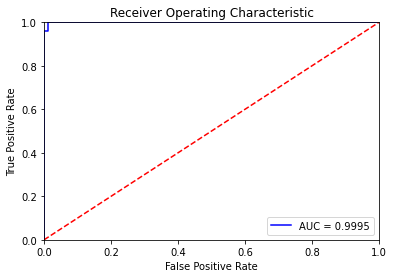

In [134]:
plot_roc_curve(y_test,score)

<h1>更换数据集</h1>

In [10]:
data2=pd.read_csv(r"ionosphere.data",',',encoding='utf-8')   #读取数据集
#显示数据集的前五条
print(data2.head())
print('删除前的数据集大小为:{}'.format(data2.shape))
data2.drop_duplicates(inplace=True)  #删除重复数据
# data.replace('?', pd.NA, inplace=True)
# data.dropna(inplace=True)   #删除缺失值
print('删除后的数据集大小为:{}'.format(data2.shape))
header=range(35)
data2.columns=header
data2=data2.drop(columns=[1])  #删除第二列
header=range(34)
data2.columns=header
# data.to_excel('ionosphere.xlsx', sheet_name='data') #写到excel里方便分析一下

   1  0  0.99539  -0.05889  0.85243  0.02306  0.83398  -0.37708      1.1  \
0  1  0  1.00000  -0.18829  0.93035 -0.36156 -0.10868  -0.93597  1.00000   
1  1  0  1.00000  -0.03365  1.00000  0.00485  1.00000  -0.12062  0.88965   
2  1  0  1.00000  -0.45161  1.00000  1.00000  0.71216  -1.00000  0.00000   
3  1  0  1.00000  -0.02401  0.94140  0.06531  0.92106  -0.23255  0.77152   
4  1  0  0.02337  -0.00592 -0.09924 -0.11949 -0.00763  -0.11824  0.14706   

   0.03760  ...  -0.51171  0.41078  -0.46168  0.21266  -0.34090  0.42267  \
0 -0.04549  ...  -0.26569 -0.20468  -0.18401 -0.19040  -0.11593 -0.16626   
1  0.01198  ...  -0.40220  0.58984  -0.22145  0.43100  -0.17365  0.60436   
2  0.00000  ...   0.90695  0.51613   1.00000  1.00000  -0.20099  0.25682   
3 -0.16399  ...  -0.65158  0.13290  -0.53206  0.02431  -0.62197 -0.05707   
4  0.06637  ...  -0.01535 -0.03240   0.09223 -0.07859   0.00732  0.00000   

   -0.54487  0.18641  -0.45300  g  
0  -0.06288 -0.13738  -0.02447  b  
1  -0.24180  0

D:\anacondainstall\lib\site-packages\IPython\core\interactiveshell.py:3331: FutureWarning: In a future version of pandas all arguments of read_csv except for the argument 'filepath_or_buffer' will be keyword-only
  exec(code_obj, self.user_global_ns, self.user_ns)


In [11]:
data2.replace({'b': 1, 'g': 0}, inplace=True)
data2[33].value_counts()

0    224
1    125
Name: 33, dtype: int64

In [19]:
n=0.8
data2 = data2.apply(pd.to_numeric)
classnumber=data.value_counts()

bad=data2[data2[33]==1]
good=data2[data2[33]==0]

bad=bad.sample(len(bad),random_state=0)
good=good.sample(len(good),random_state=0)

#分层抽样后相连,创建训练集和测试集
train_X=pd.concat([bad.iloc[:int(len(bad)*0.8),:-1],good.iloc[:int(len(good)*0.8),:-1]],axis=0)
train_y=pd.concat([bad.iloc[:int(len(bad)*0.8),-1],good.iloc[:int(len(good)*0.8),-1]],axis=0)
test_X=pd.concat([bad.iloc[int(len(bad)*0.8):,:-1],good.iloc[int(len(good)*0.8):,:-1]],axis=0)
test_y=pd.concat([bad.iloc[int(len(bad)*0.8):,-1],good.iloc[int(len(good)*0.8):,-1]],axis=0)


(279, 33)
